# Does moving the first gate hurt retention? An A/B test on Cookie Cats

**Business question.** In the mobile puzzle game *Cookie Cats*, players hit a "gate" that forces them to wait or pay before continuing. The gate sits at **level 30**. The team tested moving it to **level 40**. Should they ship the change?

**Short answer: no.** Moving the gate to level 40 lowered **7-day retention from 19.0% to 18.2%** (−0.82 percentage points, 95% CI −1.33 to −0.31, p = 0.0016). 1-day retention and early engagement showed no statistically significant change. The groups are slightly unbalanced (a sample ratio mismatch, p = 0.009), which is flagged and discussed below, but it does not change the recommendation because the recommendation is to keep the status quo.

## 1. Experiment design

| | |
|---|---|
| **Unit of randomization** | Player, assigned at install |
| **Control (A)** | `gate_30`: gate at level 30 (current) |
| **Treatment (B)** | `gate_40`: gate at level 40 |
| **Primary metric** | 7-day retention: did the player return 7 days after install? |
| **Secondary metric** | 1-day retention |
| **Engagement check** | Game rounds played in the first 14 days |
| **Significance level** | α = 0.05 overall; Bonferroni-adjusted to **0.025** per retention metric (two metrics tested) |

The primary metric is decided **before** looking at results. 7-day retention is the better proxy for long-term value: a change can look harmless on day 1 and still lose players over the following week.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ab_stats import (
    srm_check,
    two_proportion_ztest,
    bootstrap_mean_diff,
    mann_whitney,
    mde_two_proportions,
    sample_size_two_proportions,
)

# Chart styling: blue = control (gate_30), orange = treatment (gate_40).
COLORS = {"gate_30": "#2a78d6", "gate_40": "#eb6834"}
LABELS = {"gate_30": "Gate at level 30 (control)", "gate_40": "Gate at level 40 (treatment)"}
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": INK_2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "legend.frameon": False,
})
FIG_DIR = "../reports/figures"
ALPHA_PER_METRIC = 0.05 / 2  # Bonferroni across the two retention metrics

In [2]:
df = pd.read_csv("../data/cookie_cats.csv")
print(f"{len(df):,} players, {df.shape[1]} columns")
df.head()

90,189 players, 5 columns


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


## 2. Data quality checks

Before testing anything: missing values, duplicate players, and implausible values.

In [3]:
print("Missing values per column:", df.isna().sum().to_dict())
print("Duplicate player IDs:     ", df["userid"].duplicated().sum())
print()
print(df["version"].value_counts().rename("players").to_frame())

Missing values per column: {'userid': 0, 'version': 0, 'sum_gamerounds': 0, 'retention_1': 0, 'retention_7': 0}
Duplicate player IDs:      0

         players
version         
gate_40    45489
gate_30    44700


In [4]:
print(df["sum_gamerounds"].describe().round(1))
print()
print("Five largest values:", df["sum_gamerounds"].nlargest(5).tolist())
print(f"Players with 0 rounds: {(df['sum_gamerounds'] == 0).mean():.1%}")

count    90189.0
mean        51.9
std        195.1
min          0.0
25%          5.0
50%         16.0
75%         51.0
max      49854.0
Name: sum_gamerounds, dtype: float64

Five largest values: [49854, 2961, 2640, 2438, 2294]
Players with 0 rounds: 4.4%


One player logged **49,854 rounds** in their first 14 days, about 3,560 rounds a day and roughly 17 times the next-highest player. That is almost certainly a bot or a logging error rather than a real player, so it is removed. Section 7 re-runs the main test with it included to confirm the conclusion doesn't depend on this choice.

About 4% of players installed but never played a round. They are **kept**: they were randomized like everyone else, and dropping them would mean filtering on something that happens after assignment.

In [5]:
outliers = df[df["sum_gamerounds"] > 10_000]
print(outliers)
clean = df.drop(outliers.index)
print(f"\nRemoved {len(outliers)} row(s); {len(clean):,} players remain.")

        userid  version  sum_gamerounds  retention_1  retention_7
57702  6390605  gate_30           49854        False         True

Removed 1 row(s); 90,188 players remain.


## 3. Sample ratio mismatch (SRM) check

If players were split 50/50, the group sizes should be close to equal. A chi-square goodness-of-fit test checks whether the observed imbalance is bigger than chance would produce. A common alarm threshold is p < 0.01.

In [6]:
counts = clean["version"].value_counts().sort_index()
srm = srm_check(counts.values, expected_ratios=[0.5, 0.5])
share = counts / counts.sum()
print(counts.to_string())
print(f"\nShare in gate_40: {share['gate_40']:.2%}")
print(f"Chi-square = {srm['chi2']:.2f}, p = {srm['p_value']:.4f}")

version
gate_30    44699
gate_40    45489

Share in gate_40: 50.44%
Chi-square = 6.92, p = 0.0085


**There is a sample ratio mismatch.** The treatment group has about 790 more players than control (50.4% vs 49.6%), and a gap this size would occur by chance less than 1% of the time under a true 50/50 split.

What this means and doesn't mean:

- **The intended split isn't documented** in the public data. If it was never meant to be exactly 50/50, there is no problem.
- If it *was* 50/50, something in assignment or logging dropped or added players unevenly, and those players may differ systematically from the rest. That could bias the comparison in either direction.
- **This dataset can't diagnose the cause.** It has no install timestamps, platforms, or assignment logs. In a real team, the next step would be to break the imbalance down by day, platform, and app version, and to check whether one group had more players excluded by a logging filter.

**How I handle it here:** report the results with this caveat attached. The recommendation in section 8 is to keep the current design, which is the low-risk choice even if the estimate is somewhat off. If the test had pointed toward shipping a change, I would not act on it until the SRM was explained.

## 4. Was the test big enough? (Power and minimum detectable effect)

With about 45,000 players per group and a 7-day baseline near 19%, what is the smallest change this test could reliably detect (80% power, α = 0.025)?

In [7]:
n_per_group = counts.min()
base_7 = clean.loc[clean["version"] == "gate_30", "retention_7"].mean()
base_1 = clean.loc[clean["version"] == "gate_30", "retention_1"].mean()

mde_7 = mde_two_proportions(base_7, n_per_group, alpha=ALPHA_PER_METRIC, power=0.80)
mde_1 = mde_two_proportions(base_1, n_per_group, alpha=ALPHA_PER_METRIC, power=0.80)
print(f"7-day retention: baseline {base_7:.2%}, MDE = {mde_7*100:.2f} percentage points")
print(f"1-day retention: baseline {base_1:.2%}, MDE = {mde_1*100:.2f} percentage points")

n_needed = sample_size_two_proportions(base_7, 0.005, alpha=ALPHA_PER_METRIC, power=0.80)
print(f"\nPlayers per group needed to detect a 0.5 pp change in 7-day retention: {n_needed:,}")

7-day retention: baseline 19.02%, MDE = 0.81 percentage points
1-day retention: baseline 44.82%, MDE = 1.03 percentage points

Players per group needed to detect a 0.5 pp change in 7-day retention: 117,113


The test can reliably detect changes of roughly **0.8 pp** in 7-day retention and **1.0 pp** in 1-day retention. Smaller true effects could be missed, which matters when reading a non-significant result: "not significant" here means "smaller than about 1 pp, if it exists", not "zero".

## 5. Primary result: retention

Two-proportion z-tests, treatment minus control. Each p-value is compared against the Bonferroni-adjusted threshold of 0.025.

In [8]:
rows = []
for metric, label in [("retention_1", "1-day retention"), ("retention_7", "7-day retention")]:
    a = clean.loc[clean["version"] == "gate_30", metric]
    b = clean.loc[clean["version"] == "gate_40", metric]
    r = two_proportion_ztest(a.sum(), len(a), b.sum(), len(b), alpha=ALPHA_PER_METRIC)
    rows.append({
        "metric": label,
        "gate_30": f"{r['p_a']:.2%}",
        "gate_40": f"{r['p_b']:.2%}",
        "diff (pp)": round(r["diff"] * 100, 2),
        f"{1-ALPHA_PER_METRIC:.1%} CI (pp)": f"[{r['ci_low']*100:.2f}, {r['ci_high']*100:.2f}]",
        "relative change": f"{r['relative_lift']:+.1%}",
        "p-value": round(r["p_value"], 4),
        "significant": r["p_value"] < ALPHA_PER_METRIC,
    })
results = pd.DataFrame(rows).set_index("metric")
results

,gate_30,gate_40,diff (pp),97.5% CI (pp),relative change,p-value,significant
metric,,,,,,,
1-day retention,44.82%,44.23%,-0.59,"[-1.33, 0.15]",-1.3%,0.0739,False
7-day retention,19.02%,18.20%,-0.82,"[-1.40, -0.24]",-4.3%,0.0016,True


- **7-day retention fell by 0.82 pp** (19.02% → 18.20%), a 4.3% relative drop. p = 0.0016, well under the 0.025 threshold, and the 97.5% confidence interval sits entirely below zero.
- **1-day retention fell by 0.59 pp**, but p = 0.074, so it is not statistically significant. The interval includes zero.

The pattern makes product sense: the gate is a natural pause. At level 30 it arrives early enough that many players take a break and come back; pushing it to level 40 lets more players binge through the early game and lose interest by day 7.

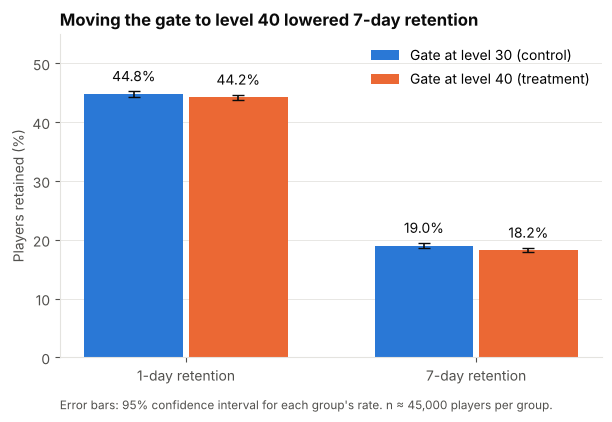

In [9]:
def wald_ci(p, n, z=1.96):
    return z * np.sqrt(p * (1 - p) / n)

fig, ax = plt.subplots(figsize=(7, 4.2))
metrics = [("retention_1", "1-day retention"), ("retention_7", "7-day retention")]
width, gap = 0.34, 0.02
for i, (metric, label) in enumerate(metrics):
    for j, version in enumerate(["gate_30", "gate_40"]):
        s = clean.loc[clean["version"] == version, metric]
        p, n = s.mean(), len(s)
        x = i + (j - 0.5) * (width + gap)
        ax.bar(x, p * 100, width, color=COLORS[version], label=LABELS[version] if i == 0 else None)
        ax.errorbar(x, p * 100, yerr=wald_ci(p, n) * 100, color=INK, capsize=4, lw=1.2)
        ax.text(x, p * 100 + 1.6, f"{p:.1%}", ha="center", va="bottom", color=INK, fontsize=10)

ax.set_xticks(range(len(metrics)), [m[1] for m in metrics])
ax.set_ylabel("Players retained (%)")
ax.set_ylim(0, 55)
ax.grid(axis="x", visible=False)
ax.set_title("Moving the gate to level 40 lowered 7-day retention", loc="left")
ax.legend(loc="upper right")
ax.text(0, -0.16, "Error bars: 95% confidence interval for each group's rate. n ≈ 45,000 players per group.",
        transform=ax.transAxes, color=INK_2, fontsize=8.5)
fig.savefig(f"{FIG_DIR}/retention_by_group.png")
plt.show()

### Bootstrap check

The z-test relies on a normal approximation. With 45,000 players per group that is safe, but a bootstrap gives the same answer without that assumption: resample each group with replacement 5,000 times and look at the spread of the difference.

In [10]:
a7 = clean.loc[clean["version"] == "gate_30", "retention_7"]
b7 = clean.loc[clean["version"] == "gate_40", "retention_7"]
boot = bootstrap_mean_diff(a7, b7, n_boot=5000, seed=42) * 100  # in percentage points

lo, hi = np.percentile(boot, [1.25, 98.75])
print(f"Bootstrap 97.5% interval for the 7-day difference: [{lo:.2f}, {hi:.2f}] pp")
print(f"Share of resamples where gate_40 retained fewer players: {(boot < 0).mean():.1%}")

Bootstrap 97.5% interval for the 7-day difference: [-1.39, -0.25] pp
Share of resamples where gate_40 retained fewer players: 99.9%


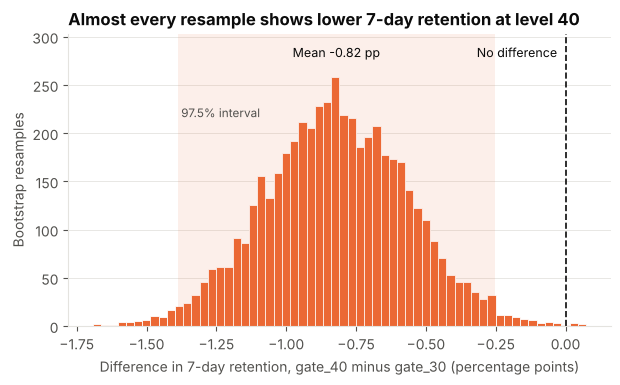

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(boot, bins=60, color=COLORS["gate_40"], edgecolor="white", linewidth=0.6)
ax.axvspan(lo, hi, color=COLORS["gate_40"], alpha=0.10, lw=0)
ax.axvline(0, color=INK, lw=1.2, ls="--")
top = ax.get_ylim()[1]
ax.set_ylim(0, top * 1.12)
ax.text(-0.03, top * 1.03, "No difference", ha="right", color=INK, fontsize=9)
ax.text(boot.mean(), top * 1.03, f"Mean {boot.mean():.2f} pp", ha="center", color=INK, fontsize=9)
ax.text(lo, top * 0.80, " 97.5% interval", ha="left", color=INK_2, fontsize=8.5)
ax.set_xlabel("Difference in 7-day retention, gate_40 minus gate_30 (percentage points)")
ax.set_ylabel("Bootstrap resamples")
ax.grid(axis="x", visible=False)
ax.set_title("Almost every resample shows lower 7-day retention at level 40", loc="left")
fig.savefig(f"{FIG_DIR}/bootstrap_7day_diff.png")
plt.show()

## 6. Engagement: game rounds in the first 14 days

Rounds played are extremely skewed (median 16, but a long tail into the thousands), so comparing means would be driven by a handful of heavy players. A **Mann-Whitney U test** compares the distributions by rank instead.

In [12]:
a_r = clean.loc[clean["version"] == "gate_30", "sum_gamerounds"]
b_r = clean.loc[clean["version"] == "gate_40", "sum_gamerounds"]
summary = pd.DataFrame({
    "median": [a_r.median(), b_r.median()],
    "mean": [a_r.mean(), b_r.mean()],
    "75th pct": [a_r.quantile(0.75), b_r.quantile(0.75)],
}, index=["gate_30", "gate_40"]).round(1)
print(summary)
mw = mann_whitney(a_r, b_r)
print(f"\nMann-Whitney U p-value: {mw['p_value']:.3f}")

         median  mean  75th pct
gate_30    17.0  51.3      50.0
gate_40    16.0  51.3      52.0

Mann-Whitney U p-value: 0.051


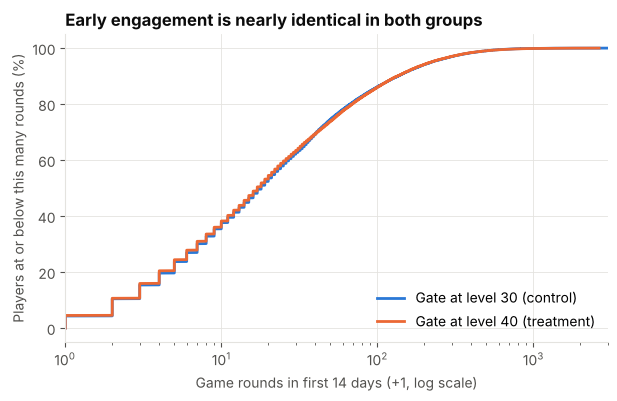

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
for version, s in [("gate_30", a_r), ("gate_40", b_r)]:
    x = np.sort(s.values) + 1  # +1 so zero rounds can sit on a log axis
    y = np.arange(1, len(x) + 1) / len(x)
    ax.plot(x, y * 100, color=COLORS[version], lw=2, label=LABELS[version])
ax.set_xscale("log")
ax.set_xlim(1, 3000)
ax.set_xlabel("Game rounds in first 14 days (+1, log scale)")
ax.set_ylabel("Players at or below this many rounds (%)")
ax.set_title("Early engagement is nearly identical in both groups", loc="left")
ax.legend(loc="lower right")
fig.savefig(f"{FIG_DIR}/gamerounds_ecdf.png")
plt.show()

The two curves almost overlap. Medians differ by one round and p = 0.051, so there is **no significant difference in early engagement**. Moving the gate didn't make players play more in their first two weeks; it just made fewer of them come back at day 7.

Rounds played is not the same as level reached (players can fail and replay levels), so this dataset can't show exactly how many players actually reached each gate.

## 7. Sensitivity check: does removing the outlier matter?

In [14]:
for label, data in [("outlier removed", clean), ("outlier included", df)]:
    a = data.loc[data["version"] == "gate_30", "retention_7"]
    b = data.loc[data["version"] == "gate_40", "retention_7"]
    r = two_proportion_ztest(a.sum(), len(a), b.sum(), len(b))
    print(f"{label:17s}  diff = {r['diff']*100:+.2f} pp   p = {r['p_value']:.4f}")

outlier removed    diff = -0.82 pp   p = 0.0016
outlier included   diff = -0.82 pp   p = 0.0016


Identical to two decimal places. The conclusion doesn't depend on the outlier decision.

## 8. Recommendation

**Keep the gate at level 30.**

| Metric | Result |
|---|---|
| 7-day retention (primary) | **−0.82 pp** (19.0% → 18.2%), p = 0.0016, significant |
| 1-day retention | −0.59 pp, p = 0.074, not significant |
| Early engagement (rounds) | No meaningful difference, p = 0.051 |

At a 4.3% relative drop in 7-day retention, moving the gate gives up returning players with no offsetting gain in engagement.

**Caveats**

1. **Sample ratio mismatch (p = 0.009).** The groups are slightly unbalanced. If the intended split was 50/50, the cause should be found before this pipeline is trusted for future tests. It doesn't change this decision, since the decision is to keep the current design.
2. **Short horizon.** The data stops at day 7 retention and 14-day rounds. Longer-term retention and revenue (in-app purchases at the gate) aren't observed; a later gate could plausibly change purchase behavior.
3. **Small effects can hide.** The test could miss changes smaller than about 1 pp, so "no change in 1-day retention" means "no change larger than about 1 pp".

**What I'd do next**

- Investigate the SRM: break down assignment counts by install date and platform.
- Re-run with revenue and 30-day retention if those are available.
- If the team wants to explore gate placement further, test an *earlier* gate (e.g. level 25), since the evidence points to an early pause helping retention.

---
*Data: Cookie Cats A/B test, about 90,000 players, originally released for a DataCamp project and widely mirrored. See `data/README.md` for details.*